# Coconut（Chain of Continuous Thought）

Coconut は、LLM の隠れ状態を次の入力埋め込みとして渡す推論手法です。このノートブックでは、既存の補足資料に沿って、通常の Chain of Thought（CoT）との違い、段階的な学習、探索の例を確認します。

**CoT（Chain of Thought、思考の連鎖）**は、質問から最終回答に至るまでの中間ステップを、文章や数式の列として表す方法です。

たとえば芝刈りの問題では、「4か月に1回刈る → 年に3回刈る → 1回100ドルなので年300ドル」と順に示します。第3節では最終回答だけを教師として与える学習を、第4節では中間ステップも教師として与える学習を扱います。



CoT のプロンプト例は [プロンプト設計](8300.0110.prompting_and_reliability.ipynb)、GSM8K・ProntoQA・ProsQA の違いは [Q&A データセット](8300.0180.LLM_QA_datasets.ipynb) を参照してください。

## 1. Coconut の概要

**原論文**  Shibo Hao, Sainbayar Sukhbaatar, DiJia Su, Xian Li, Zhiting Hu, Jason Weston, and Yuandong Tian. *Training Large Language Models to Reason in a Continuous Latent Space*. COLM 2025. arXiv 初版は2024年12月9日公開で、この補足資料は v3 を参照しています。 [arXiv 初版](https://arxiv.org/abs/2412.06769v1) · [arXiv v3](https://arxiv.org/abs/2412.06769v3) · [PDF（v3）](https://arxiv.org/pdf/2412.06769v3)

Coconut（Chain of Continuous Thought）は、LLM の最後の隠れ状態を、次の入力埋め込みとして直接渡す手法です。推論の途中で単語を生成する代わりに、連続値のベクトルを使います。論文では、連続表現が複数の候補を保持しうることを、幅優先探索に似た挙動として解釈しています。

## 2. トークン・埋め込み・隠れ状態

| 記号 | 意味 |
|---|---|
| $x_t$ | 位置 $t$ のトークン |
| $e_t=e(x_t)$ | トークンの入力埋め込み |
| $h_t$ | 位置 $t$ における Transformer の隠れ状態 |

「猫」のトークン埋め込みが同じでも、隠れ状態は先行する文脈によって変わります。

- 吾輩は**猫**（である、を飼っている、…）
- 今日は**猫**（に餌を与えるのが遅くなった、がリビングに居ない、…）

括弧内は後続する生成の候補です。

## 3. CoT を使わない学習

**GSM8K（Grade School Math 8K）**は、小学校レベルの算数の文章題を約8,500問収録したデータセットです。文章から必要な数量と条件を読み取り、複数の計算を組み合わせて答えを出せるかを評価するために使われます。各問題には、途中の解法と最終的な数値の答えが付いています。 [GSM8K の原論文](https://arxiv.org/abs/2110.14168)

GSM8K の例では、ジョンが芝を 2 インチに刈ります。芝は毎月 0.5 インチ伸び、4 インチに達するたびに 100 ドルで刈ります。年間の費用はいくらでしょうか。

CoT を使わない場合は、質問 $Q$ に対して答え $A$（300 ドル）を教師として与えます。質問部分も損失に含める場合、資料の略記は次のように表せます。

$$
L=-\log P(Q)-\log P(A\mid Q).
$$

自己回帰モデルの系列の負の対数尤度は、各トークンの負の対数尤度の和です。

$$
L=-\sum_t \log P(x_t\mid x_{<t}).
$$

## 4. CoT を使う学習

同じ問題で、答えに至る途中のステップ $S_1,\ldots,S_k$ も教師として与えます。

1. $4-2=2$ インチ伸びたら刈る。
2. $2/0.5=4$ か月ごとに刈る。
3. $12/4=3$ 回、年に刈る。
4. $100\times3=300$ ドルかかる。

$$
L=-\log P(Q)
  -\sum_{i=1}^{k}\log P(S_i\mid Q,S_{<i})
  -\log P(A\mid Q,S_{1:k}).
$$

## 5. 回答の評価と学習方法

答えが同じでも、`300`、`The answer is 300.`、`He pays 300.` のように表現は異なります。補足資料は、教師の回答例を学習に使う方法と、候補の回答を評価して報酬に使う方法を比較しています。

## 6. 教師ありファインチューニングと人の評価

- **SFT（Supervised Fine-Tuning）**では、質問 $Q$ に対し、教師として与えた答え $A$、または推論過程と答え $(R,A)$ の条件付き尤度を高めます。資料の採点例では、プログラムで `300` との完全一致を判定します。
- **RLHF（Reinforcement Learning from Human Feedback）**の報酬の説明では、人の評価に基づき、数値の正しさや文章の自然さに段階をつけます。たとえば `300` は 10 点、数値は正しいが文法に誤りのある `The answer are 300.` は 9 点、金額が違う `He pays 10.` は 1 点とする例です。

## 7. AI による教師データ生成と蒸留

別のモデルや過去のモデルに回答候補を生成・採点させ、教師データを作る方法があります。AI の評価を報酬に使う方法もあります。

候補を集める方法として、資料では自己対戦（self-play）と探索（search）を挙げています。探索では、同じ質問に対する複数の推論経路を試し、たとえば最終結果が 300 ドルになる経路を教師候補にします。最終答えの照合だけでは、途中の推論の妥当性までは確認できません。

## 8. カリキュラム学習

簡単な問題から始め、少し難しい問題、難しい問題へと段階的に進む学習方法です。Coconut の例では、文章で表す推論ステップを潜在表現へ段階的に置き換えます。

## 9. CoT の限界と Coconut の段階的学習

貪欲デコードでは、LM ヘッドが与える次トークンの分布から、最大確率の候補を一つ選びます。

$$
x_{t+1}=\arg\max_x P(x\mid x_{\leq t}).
$$

Coconut では、隠れ状態を次の入力へ渡す潜在ステップを導入します。

| 段階 | 質問から答えまで |
|---|---|
| 1 | 質問 → 推論 1 → 推論 2 → 答え |
| 2 | 質問 → 潜在ステップ → 推論 2 → 答え |
| 3 | 質問 → 潜在ステップ → 潜在ステップ → 答え |

残っている推論文と答えをトークンの教師として使い、潜在ステップには単語の正解ラベルを直接与えません。段階ごとに学習が必要です。

## 10. Coconut と蒸留の比較

蒸留では、教師モデルが生成した質問・推論過程・答えなどを使って別のモデルを学習させることができます。Coconut では、明示的な推論ステップを潜在ステップへ置き換えます。資料では、文章で表していた推論を潜在表現へ移すという意味で、蒸留との類似を指摘しています。

## 11. ProsQA での評価

ProsQA の問題形式と解答例は [Q&A データセット](8300.0180.LLM_QA_datasets.ipynb) にまとめています。Coconut 論文では、ProsQA の最終回答の正答率は通常の CoT が 77.5%、Coconut が 97.0% でした。次の経路探索の例で、複数の候補がある場合の違いを考えます。 [Coconut 原論文の実験結果](https://arxiv.org/html/2412.06769v3)

## 12. 経路探索の例

東京から奈良へ向かう経路を考えます。東京 → 名古屋 → 奈良と進む経路のほか、名古屋から大阪を経由して奈良に向かう経路があります。

- **貪欲探索**では、各段階で確率が最大の候補を選びます。図の例では、東京から那覇を選ぶと奈良に到達できません。
- **幅優先探索（BFS）**では、同じ深さの候補を順に調べます。札幌・那覇・金沢・名古屋を候補として残すことで、名古屋を経由する経路も探索できます。

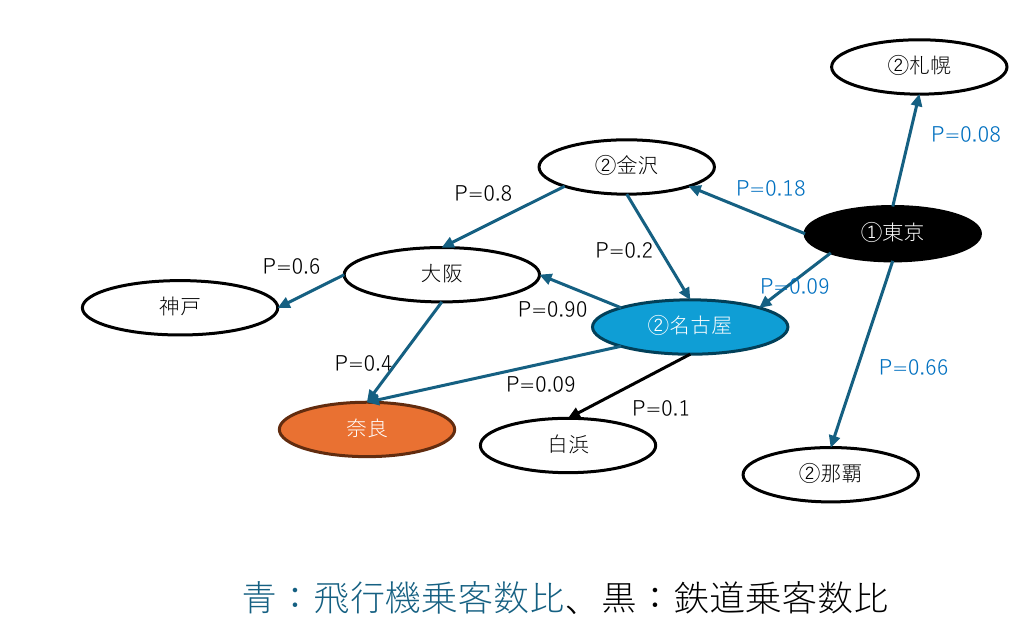

## 13. 潜在空間の解析

質問 → 潜在ステップ → 潜在ステップ → 答えという処理の途中で、潜在表現を解析すると、複数の候補が表れ、段階を追って絞られるように見えたと資料は説明しています。この観察が、Coconut の挙動を「幅優先探索に似ている」と表現する根拠です。

## 補足：推論時に使う計算量（effort）

推論時に使う計算の予算を増やすと、難しい問題で候補の比較や検証に使える余地が増える一方、応答時間や消費するトークン数も増える場合があります。具体的な実装はモデルに依存します。Coconut の潜在ステップは、隠れ状態を次の入力に渡して推論する方式です。潜在ステップの実験と、推論全般で使う計算量の設定は、別の観点です。

## 関連実習

[一次方程式の SFT 実習](8300.2001.SFT.linear_equations.ipynb)では、文章で書いた途中式を教師に含める条件と、答えだけを教師にする条件を比較します。